In [2]:
import numpy as np

a = 1
print(a)

1


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']
%matplotlib inline

In [4]:
df1 = pd.read_excel('data/meal_order_detail.xlsx',sheet_name='meal_order_detail1')
df2 = pd.read_excel('data/meal_order_detail.xlsx',sheet_name='meal_order_detail2')
df3 = pd.read_excel('data/meal_order_detail.xlsx',sheet_name='meal_order_detail3')
df = pd.concat([df1,df2,df3],axis=0)

In [5]:
df.head(5)

,detail_id,order_id,dishes_id,logicprn_name,parent_class_name,dishes_name,itemis_add,counts,amounts,cost,place_order_time,discount_amt,discount_reason,kick_back,add_inprice,add_info,bar_code,picture_file,emp_id
0,2956,417,610062,NaN,NaN,蒜蓉生蚝,0,1,49,NaN,2016-08-01 11:05:36,NaN,NaN,NaN,0,NaN,NaN,caipu/104001.jpg,1442
1,2958,417,609957,NaN,NaN,蒙古烤羊腿,0,1,48,NaN,2016-08-01 11:07:07,NaN,NaN,NaN,0,NaN,NaN,caipu/202003.jpg,1442
2,2961,417,609950,NaN,NaN,大蒜苋菜,0,1,30,NaN,2016-08-01 11:07:40,NaN,NaN,NaN,0,NaN,NaN,caipu/303001.jpg,1442
3,2966,417,610038,NaN,NaN,芝麻烤紫菜,0,1,25,NaN,2016-08-01 11:11:11,NaN,NaN,NaN,0,NaN,NaN,caipu/105002.jpg,1442
4,2968,417,610003,NaN,NaN,蒜香包,0,1,13,NaN,2016-08-01 11:11:30,NaN,NaN,NaN,0,NaN,NaN,caipu/503002.jpg,1442


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10037 entries, 0 to 3610
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   detail_id          10037 non-null  int64         
 1   order_id           10037 non-null  int64         
 2   dishes_id          10037 non-null  int64         
 3   logicprn_name      0 non-null      float64       
 4   parent_class_name  0 non-null      float64       
 5   dishes_name        10037 non-null  object        
 6   itemis_add         10037 non-null  int64         
 7   counts             10037 non-null  int64         
 8   amounts            10037 non-null  int64         
 9   cost               0 non-null      float64       
 10  place_order_time   10037 non-null  datetime64[ns]
 11  discount_amt       0 non-null      float64       
 12  discount_reason    0 non-null      float64       
 13  kick_back          0 non-null      float64       
 14  add_inprice 

In [7]:
df.dropna(axis=1,inplace=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10037 entries, 0 to 3610
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   detail_id         10037 non-null  int64         
 1   order_id          10037 non-null  int64         
 2   dishes_id         10037 non-null  int64         
 3   dishes_name       10037 non-null  object        
 4   itemis_add        10037 non-null  int64         
 5   counts            10037 non-null  int64         
 6   amounts           10037 non-null  int64         
 7   place_order_time  10037 non-null  datetime64[ns]
 8   add_inprice       10037 non-null  int64         
 9   picture_file      10037 non-null  object        
 10  emp_id            10037 non-null  int64         
dtypes: datetime64[ns](1), int64(8), object(2)
memory usage: 941.0+ KB


In [8]:
df.head(5)

,detail_id,order_id,dishes_id,dishes_name,itemis_add,counts,amounts,place_order_time,add_inprice,picture_file,emp_id
0,2956,417,610062,蒜蓉生蚝,0,1,49,2016-08-01 11:05:36,0,caipu/104001.jpg,1442
1,2958,417,609957,蒙古烤羊腿,0,1,48,2016-08-01 11:07:07,0,caipu/202003.jpg,1442
2,2961,417,609950,大蒜苋菜,0,1,30,2016-08-01 11:07:40,0,caipu/303001.jpg,1442
3,2966,417,610038,芝麻烤紫菜,0,1,25,2016-08-01 11:11:11,0,caipu/105002.jpg,1442
4,2968,417,610003,蒜香包,0,1,13,2016-08-01 11:11:30,0,caipu/503002.jpg,1442


In [9]:
round(df['amounts'].mean(),2)

np.float64(44.82)

In [10]:
np.mean(df['amounts'])

np.float64(44.821360964431605)

0 323
1 269
2 239
3 216
4 189
5 188
6 187
7 186
8 178
9 173


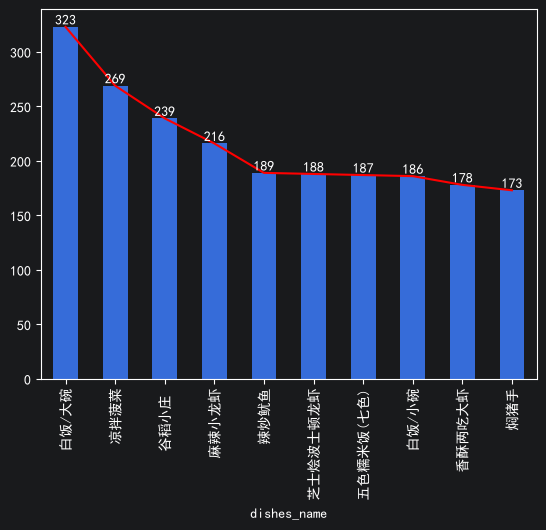

In [11]:
# 最受欢迎，频数统计
dishes_count = df['dishes_name'].value_counts()[:10]
dishes_count.plot(kind='line',color='red')
dishes_count.plot(kind='bar')
for x,y in enumerate(dishes_count):
    print(x,y)
    plt.text(x,y+2,y,ha='center')

Text(0.5, 1.0, 'ID点菜数量TOP10')

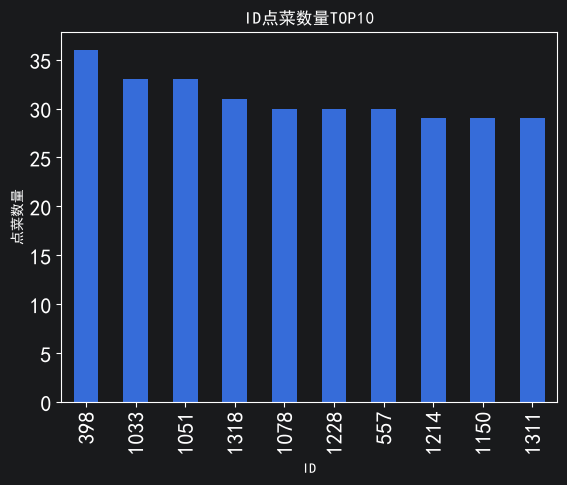

In [12]:
df['total_amounts'] = df['counts']*df['amounts']
dfGroup = df[['order_id','counts','amounts','total_amounts']].groupby('order_id')
group_sum = dfGroup.sum()
sort_counts = group_sum.sort_values(by='counts',ascending=False)
sort_counts['counts'][:10].plot(kind='bar',fontsize=16)
plt.xlabel('ID')
plt.ylabel('点菜数量')
plt.title('ID点菜数量TOP10')

<Axes: xlabel='hour'>

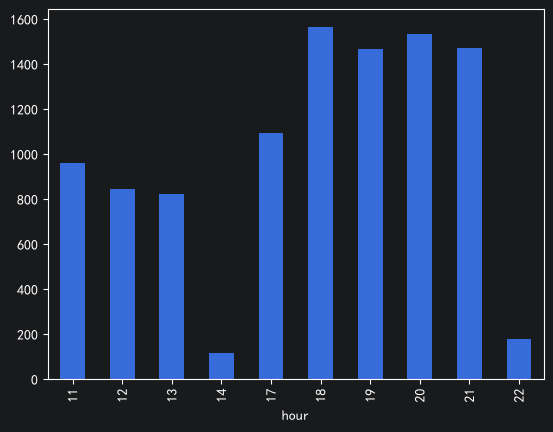

In [15]:
#一天中点菜集中时间段
df['hourcount'] = 1
df['time'] = pd.to_datetime(df['place_order_time'])
df['hour'] = df['time'].map(lambda x: x.hour)
gp_by_hour = df.groupby('hour').count()['hourcount']
gp_by_hour.plot(kind='bar')


<Axes: xlabel='day'>

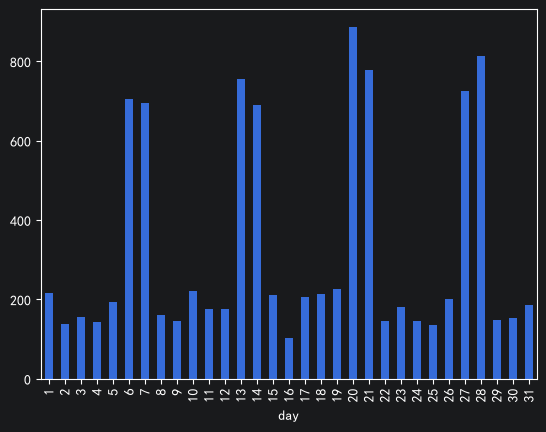

In [17]:
df['daycount'] = 1
df['day'] = df['time'].map(lambda x: x.day)
gp_by_day = df.groupby('day').count()['daycount']
gp_by_day.plot(kind='bar')